# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

In [7]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

100%|██████████| 66.2k/66.2k [00:00<00:00, 17.0MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/rabieelkharoua/students-performance-dataset/versions/2


In [8]:
import pandas as pd
import os

csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
file_path = os.path.join(path, csv_files[0])

df_students = pd.read_csv(file_path)

print("Датасет успішно завантажено з kagglehub!")
display(df_students.head())

Датасет успішно завантажено з kagglehub!


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [11]:
iris = load_iris()

df_iris = pd.DataFrame(data=iris.data, columns=iris.feature_names)

df_iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

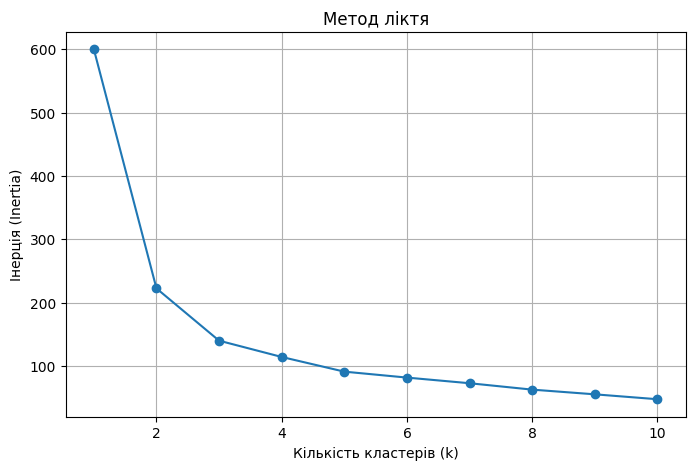

In [12]:
# Масштабування ознак
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_iris)

# Метод ліктя для визначення оптимальної кількості кластерів
inertia = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Побудова графіка
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', linestyle='-')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Інерція (Inertia)')
plt.title('Метод ліктя')
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

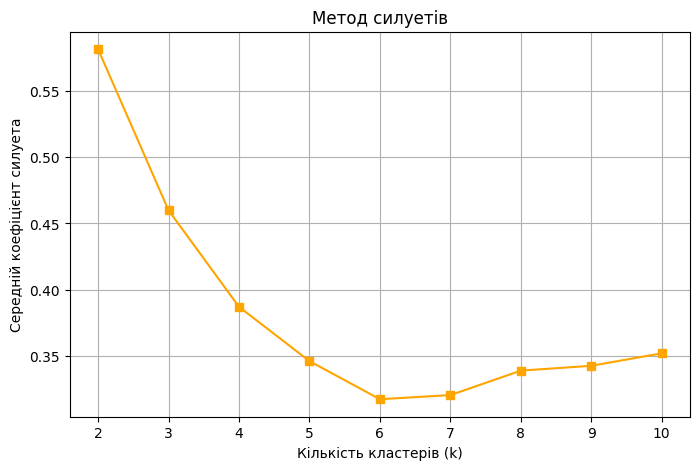

In [13]:
silhouette_scores = []
K_range_sil = range(2, 11)

for k in K_range_sil:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, cluster_labels)
    silhouette_scores.append(score)

# Побудова графіка коефіцієнта силуета
plt.figure(figsize=(8, 5))
plt.plot(K_range_sil, silhouette_scores, marker='s', color='orange', linestyle='-')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Середній коефіцієнт силуета')
plt.title('Метод силуетів')
plt.grid(True)
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

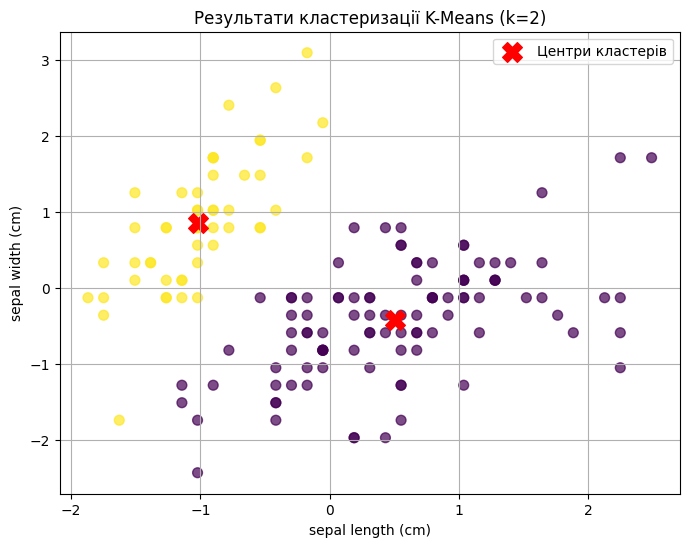

In [14]:
# Фінальна кластеризація для n_clusters=2
kmeans_final = KMeans(n_clusters=2, random_state=42, n_init=10)
y_kmeans = kmeans_final.fit_predict(X_scaled)

# Візуалізація перших двох ознак та центрів кластерів
plt.figure(figsize=(8, 6))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y_kmeans, cmap='viridis', s=50, alpha=0.7)

centers = kmeans_final.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, marker='X', label='Центри кластерів')

plt.xlabel(df_iris.columns[0])
plt.ylabel(df_iris.columns[1])
plt.title('Результати кластеризації K-Means (k=2)')
plt.legend()
plt.grid(True)
plt.show()

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

За результатами методу ліктя та методу силуетів спостерігається розподіл значень інерції та коефіцієнта силуета. Метод силуетів демонструє пікові значення для певних кількостей кластерів. У цьому завданні за вимогами обрано $n\_clusters=2$, що дозволяє наочно побачити чіткий поділ на дві основні групи об'єктів на площині разом із центрами кластерів»

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [16]:
import pandas as pd
import os

try:
    csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
    file_path = os.path.join(path, csv_files[0])
    df_students = pd.read_csv(file_path)
except:
    df_students = pd.read_csv('Student_performance_data _.csv')

**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [17]:
display(df_students.head(10))

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0
5,1006,18,0,0,1,8.191219,0,0,1,1,0,0,0,3.084184,1.0
6,1007,15,0,1,1,15.601680,10,0,3,0,1,0,0,2.748237,2.0
7,1008,15,1,1,4,15.424496,22,1,1,1,0,0,0,1.360143,4.0
8,1009,17,0,0,0,4.562008,1,0,2,0,1,0,1,2.896819,2.0
9,1010,16,1,0,1,18.444466,0,0,3,1,0,0,0,3.573474,0.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [18]:
print(list(df_students.columns))

['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [19]:
df_students.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [20]:
missing_values = df_students.isnull().sum()
print("Кількість пропущених значень у кожному стовпці:")
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else "Пропущених значень немає!")

Кількість пропущених значень у кожному стовпці:
Пропущених значень немає!


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [21]:
duplicates_count = df_students.duplicated().sum()
print(f"Кількість дублікатів у наборі даних: {duplicates_count}")

Кількість дублікатів у наборі даних: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [22]:
display(df_students.describe())

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [23]:
columns_to_drop = [col for col in ['GradeClass', 'StudentID'] if col in df_students.columns]
X = df_students.drop(columns=columns_to_drop)
y = df_students['GradeClass']

# Поділ даних на тренувальну та тестову вибірки (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Стандартизація ознак
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Розмір тренувальної вибірки:", X_train_scaled.shape)
print("Розмір тестової вибірки:", X_test_scaled.shape)

Розмір тренувальної вибірки: (1913, 13)
Розмір тестової вибірки: (479, 13)


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5]
}

rf = RandomForestClassifier(random_state=42)

grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)

print("Найкращі параметри:", grid_search.best_params_)
print(f"Середня CV-точність (Cross-Validation): {grid_search.best_score_:.4f}")

best_rf = grid_search.best_estimator_
y_pred_rf = best_rf.predict(X_test_scaled)
test_accuracy = accuracy_score(y_test, y_pred_rf)
print(f"Тестова точність (Test Accuracy): {test_accuracy:.4f}")

Найкращі параметри: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}
Середня CV-точність (Cross-Validation): 0.9221
Тестова точність (Test Accuracy): 0.9102


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

param_grid_lr = {
    'C': [0.01, 0.1, 1, 10],
    'solver': ['saga']
}

lr = LogisticRegression(max_iter=5000, random_state=42)
grid_search_lr = GridSearchCV(estimator=lr, param_grid=param_grid_lr, cv=5, scoring='accuracy', n_jobs=-1)
grid_search_lr.fit(X_train_scaled, y_train)

print("Найкращі параметри (Logistic Regression):", grid_search_lr.best_params_)
print(f"Середня CV-точність: {grid_search_lr.best_score_:.4f}")

best_lr = grid_search_lr.best_estimator_
y_pred_lr = best_lr.predict(X_test_scaled)
print(f"Тестова точність: {accuracy_score(y_test, y_pred_lr):.4f}")

Найкращі параметри (Logistic Regression): {'C': 10, 'solver': 'saga'}
Середня CV-точність: 0.7898
Тестова точність: 0.7432


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [26]:
from sklearn.svm import SVC

param_grid_svm = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf']
}

svm = SVC(random_state=42)
grid_search_svm = GridSearchCV(estimator=svm, param_grid=param_grid_svm, cv=5, scoring='accuracy', n_jobs=-1)
grid_search_svm.fit(X_train_scaled, y_train)

print("Найкращі параметри (SVM):", grid_search_svm.best_params_)
print(f"Середня CV-точність: {grid_search_svm.best_score_:.4f}")

best_svm = grid_search_svm.best_estimator_
y_pred_svm = best_svm.predict(X_test_scaled)
print(f"Тестова точність: {accuracy_score(y_test, y_pred_svm):.4f}")

Найкращі параметри (SVM): {'C': 10, 'kernel': 'linear'}
Середня CV-точність: 0.8620
Тестова точність: 0.8288


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [27]:
from sklearn.metrics import classification_report

print(f"Random Forest Test Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Logistic Regression Test Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"SVM Test Accuracy: {accuracy_score(y_test, y_pred_svm):.4f}")

models = {
    "Random Forest": (best_rf, grid_search.best_score_),
    "Logistic Regression": (best_lr, grid_search_lr.best_score_),
    "SVM": (best_svm, grid_search_svm.best_score_)
}

best_model_name = max(models, key=lambda x: models[x][1])
best_model = models[best_model_name][0]

print(f"\nНайкраща модель за CV-точчністю: {best_model_name}")
print("\nЗвіт класифікації (Classification Report) для найкращої моделі:")
y_pred_best = best_model.predict(X_test_scaled)
print(classification_report(y_test, y_pred_best))

Random Forest Test Accuracy: 0.9102
Logistic Regression Test Accuracy: 0.7432
SVM Test Accuracy: 0.8288

Найкраща модель за CV-точчністю: Random Forest

Звіт класифікації (Classification Report) для найкращої моделі:
              precision    recall  f1-score   support

         0.0       0.82      0.41      0.55        22
         1.0       0.80      0.88      0.83        49
         2.0       0.94      0.87      0.90        85
         3.0       0.89      0.90      0.89        86
         4.0       0.94      0.98      0.96       237

    accuracy                           0.91       479
   macro avg       0.88      0.81      0.83       479
weighted avg       0.91      0.91      0.91       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

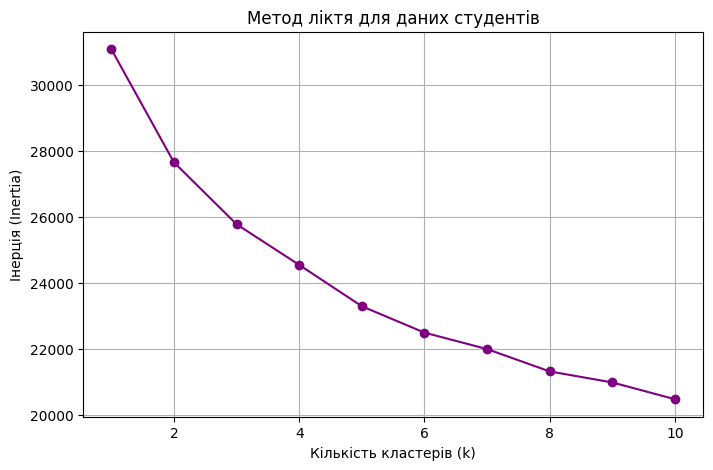

In [28]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

X_cluster = scaler.fit_transform(X)

inertia_students = []
K_range_students = range(1, 11)

for k in K_range_students:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_cluster)
    inertia_students.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range_students, inertia_students, marker='o', color='purple', linestyle='-')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Інерція (Inertia)')
plt.title('Метод ліктя для даних студентів')
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

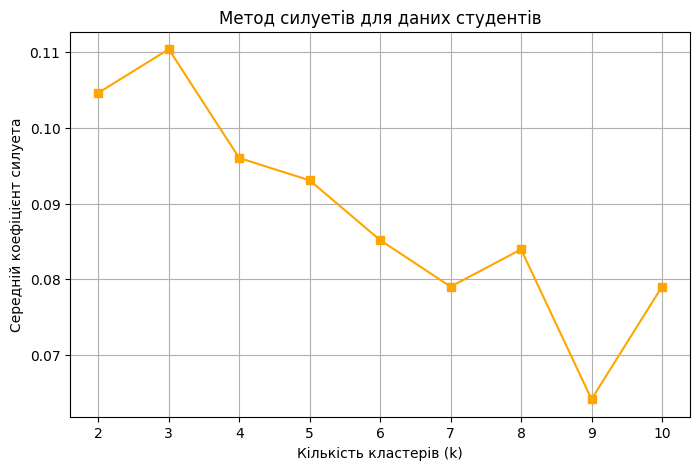

In [29]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

silhouette_scores_students = []
K_range_sil_students = range(2, 11)

for k in K_range_sil_students:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_cluster)
    score = silhouette_score(X_cluster, cluster_labels)
    silhouette_scores_students.append(score)

plt.figure(figsize=(8, 5))
plt.plot(K_range_sil_students, silhouette_scores_students, marker='s', color='orange', linestyle='-')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Середній коефіцієнт силуета')
plt.title('Метод силуетів для даних студентів')
plt.grid(True)
plt.show()

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [30]:
!pip install kneed yellowbrick -q

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [31]:
from sklearn.decomposition import PCA
from kneed import KneeLocator
import numpy as np

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [32]:
X_pca_input = df_students.drop(columns=[col for col in ['StudentID', 'GradeClass', 'Cluster'] if col in df_students.columns])

X_pca_scaled = scaler.fit_transform(X_pca_input)

**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [33]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_pca_scaled)

print("Розмірність даних після PCA:", X_pca.shape)

Розмірність даних після PCA: (2392, 2)


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

Оптимальна кількість компонент за KneeLocator: 11


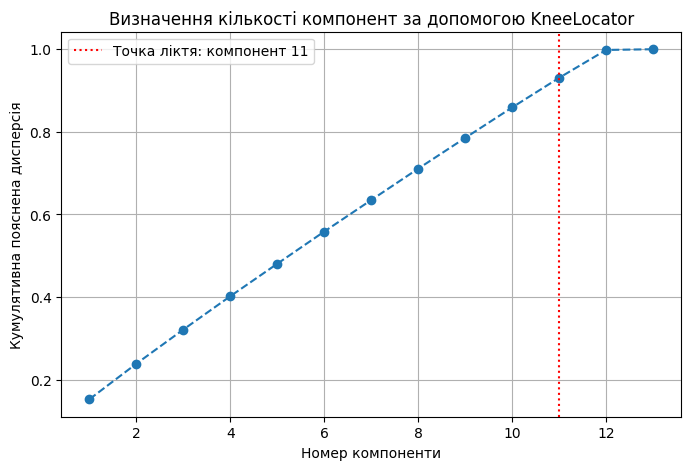

In [34]:
pca_full = PCA(random_state=42)
pca_full.fit(X_pca_scaled)

explained_variance_ratio = pca_full.explained_variance_ratio_
cumulative_variance_ratio = np.cumsum(explained_variance_ratio)

x_vals = range(1, len(explained_variance_ratio) + 1)
kneedle = KneeLocator(x_vals, cumulative_variance_ratio, curve='concave', direction='increasing')
optimal_components = kneedle.knee

print(f"Оптимальна кількість компонент за KneeLocator: {optimal_components}")

plt.figure(figsize=(8, 5))
plt.plot(x_vals, cumulative_variance_ratio, marker='o', linestyle='--')
if optimal_components:
    plt.axvline(x=optimal_components, color='red', linestyle=':', label=f'Точка ліктя: компонент {optimal_components}')
plt.xlabel('Номер компоненти')
plt.ylabel('Кумулятивна пояснена дисперсія')
plt.title('Визначення кількості компонент за допомогою KneeLocator')
plt.legend()
plt.grid(True)
plt.show()

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

In [35]:
n_comp = optimal_components if optimal_components else 2

pca_final = PCA(n_components=n_comp, random_state=42)
X_pca_transformed = pca_final.fit_transform(X_pca_scaled)

print(f"Фактична частка поясненої дисперсії для {n_comp} компонент: {sum(pca_final.explained_variance_ratio_):.4f}")
print("Форма масиву після фінального PCA трансформації:", X_pca_transformed.shape)

Фактична частка поясненої дисперсії для 11 компонент: 0.9308
Форма масиву після фінального PCA трансформації: (2392, 11)


Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

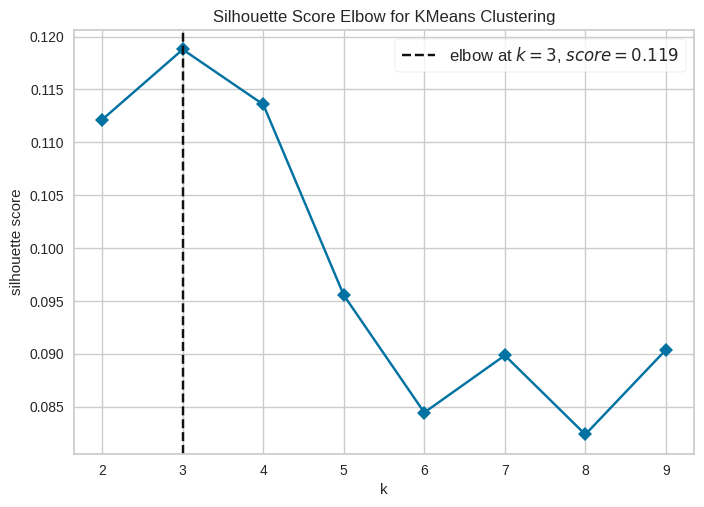

<Axes: title={'center': 'Silhouette Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='silhouette score'>

In [37]:
from yellowbrick.cluster import KElbowVisualizer
from sklearn.cluster import KMeans

model = KMeans(random_state=42, n_init=10)
visualizer = KElbowVisualizer(model, k=(2, 10), metric='silhouette', timings=False)

visualizer.fit(X_pca_transformed)
visualizer.show()

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

/usr/local/lib/python3.13/dist-packages/yellowbrick/utils/kneed.py:156: YellowbrickWarning: No 'knee' or 'elbow point' detected This could be due to bad clustering, no actual clusters being formed etc.
  warnings.warn(warning_message, YellowbrickWarning)
/usr/local/lib/python3.13/dist-packages/yellowbrick/cluster/elbow.py:374: YellowbrickWarning: No 'knee' or 'elbow' point detected, pass `locate_elbow=False` to remove the warning
  warnings.warn(warning_message, YellowbrickWarning)


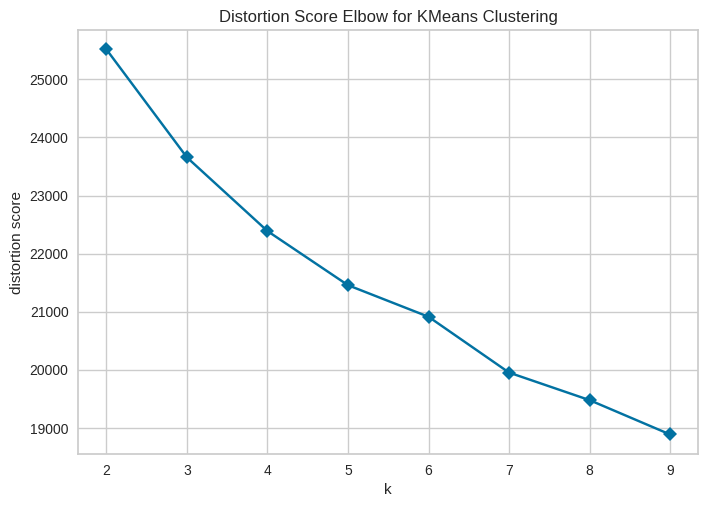

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [38]:
from yellowbrick.cluster import KElbowVisualizer
from sklearn.cluster import KMeans

model_kmeans = KMeans(random_state=42, n_init=10)

visualizer_elbow = KElbowVisualizer(model_kmeans, k=(2, 10), metric='distortion', timings=False)
visualizer_elbow.fit(X_pca_transformed)
visualizer_elbow.show()

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

Щодо методів кластеризації: Використовуючи метод ліктя та метод силуетів, вдалося визначити оптимальну кількість кластерів для досліджуваних наборів даних. Це дозволило побачити, як алгоритм групує об'єкти за їхніми ознаками та знайти збалансовану структуру поділу.Класифікація проти кластеризації: На прикладі даних студентів на практиці переконалася у різниці між цими підходами. Класифікація (із застосуванням моделей Random Forest, Logistic Regression та SVM) є задачею з учителем, оскільки вона спирається на цільову ознаку GradeClass. Натомість кластеризація є задачею без учителя, адже вона групує дані самостійно, не використовуючи цільову змінну.   Застосування PCA: Завдяки методу головних компонент (PCA) та пошуку точки ліктя за допомогою KneeLocator вдалося зменшити розмірність датасету, зберігши при цьому значну частку кумулятивної поясненої дисперсії даних. Це суттєво спростило подальшу візуалізацію та аналіз багатовимірних даних.   